## Representacióm Bag of Words (BoW)

### Fundamento Matemático

El modelo **Bag of Words (BoW)** o Bolsa de Palabras es una representación simplificada utilizada en el procesamiento de lenguaje natural. En este modelo, un texto (como una estrofa o documento) se representa como el conjunto (bolsa) de sus palabras, ignorando la gramática y el orden de las palabras, pero manteniendo su multiplicidad.

Matemáticamente, dado un corpus $D$ compuesto por $M$ documentos $\{d_1, d_2, \dots, d_M\}$, primero construimos un **vocabulario** único $V$ de tamaño $N$:

$$V = \{w_1, w_2, \dots, w_N\}$$

Cada documento $d_i$ se vectoriza como un vector fila $\mathbf{v}_i$ de dimensión $N$:

$$\mathbf{v}_i = [f_{i,1}, f_{i,2}, \dots, f_{i,N}]$$

Donde $f_{i,j}$ es la **frecuencia absoluta** (número de apariciones) del término $w_j$ en el documento $d_i$:

$$f_{i,j} = \text{count}(w_j, d_i)$$

La unión de todos estos vectores para el corpus entero forma la **Matriz de Términos-Documentos** $\mathbf{X} \in \mathbb{R}^{M \times N}$.


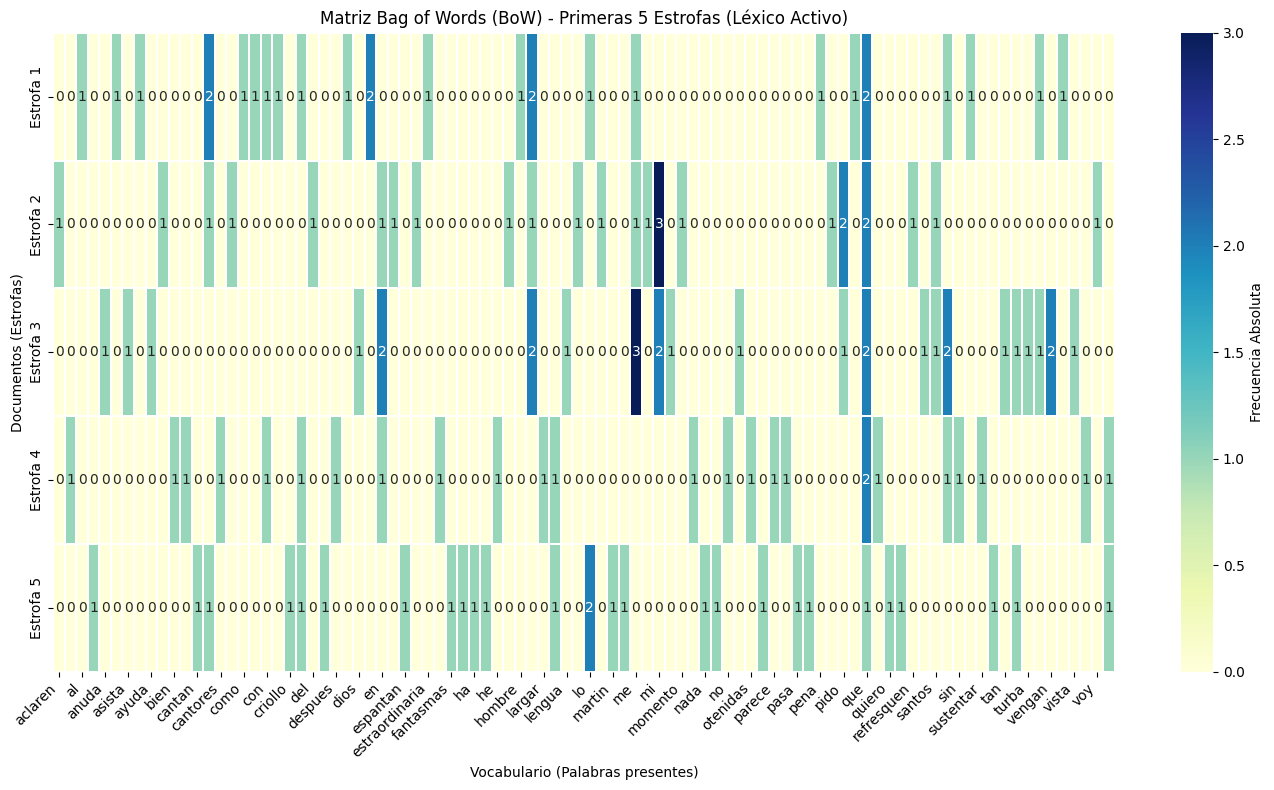

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os
import random
import requests
import unicodedata

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import PCA
from collections import defaultdict, Counter
from typing import Iterable, Callable

In [ ]:
class Corpus():
  def __init__(self, documents):
    self.raw_documents = documents

  def get_raw_documents(self):
    return self.raw_documents

  def sample(self, lenght=3):
    for i in range(min(lenght, len(self.raw_documents))):
      print(f'\n ==== Document {i+1} ==== \n\n{self.raw_documents[i][:250]}')

In [ ]:
class DocumentsCleaner():

    @staticmethod
    def _transform(
        documents: Iterable[str],
        function: Callable[[str], str],
        *,
        discard_empty: bool = False
    ) -> list[str]:
        """Aplica una transformación y devuelve una nueva lista."""
        result = [function(document) for document in documents]
        return [doc for doc in result if doc] if discard_empty else result

    def delete_init_final_chars(self, documents):
        """Elimina espacios al inicio y al final y descarta documentos vacíos."""
        return self._transform(
            documents, str.strip, discard_empty=True
        )

    def to_lower_case(self, documents):
        """Convierte los documentos a minúsculas."""
        return self._transform(documents, str.lower)

    def delete_accents(self, documents):
        """Elimina los diacríticos de los documentos."""
        def remove_accents(document):
            return ''.join(
                char
                for char in unicodedata.normalize('NFD', document)
                if unicodedata.category(char) != 'Mn'
            )

        return self._transform(documents, remove_accents)

    def conserve_letters_numbers_spaces_and_signs(self, documents):
        """Conserva los caracteres permitidos."""
        pattern = re.compile(r'[^a-zñ0-9\s.,;:¿?¡!"“”\'()\-—…]')

        return self._transform(
            documents,
            lambda document: pattern.sub('', document)
        )

    def normalize_multiple_spaces(self, documents):
        """Reduce los espacios consecutivos a uno solo."""
        return self._transform(
            documents,
            lambda document: re.sub(r'\s+', ' ', document).strip()
        )

    def conserve_documents_with_than_words(self, documents, n=5):
        """Conserva documentos con más de n palabras."""
        return [
            document
            for document in documents
            if document and len(document.split()) > n
        ]

    def apply_rgx(self, documents, rgx):
        """Descarta documentos que coinciden con el patrón
        o que tienen menos de dos líneas.
        """
        pattern = re.compile(rgx)

        return [
            document
            for document in documents
            if not pattern.match(document)
            and len(document.split('\n')) >= 2
        ]

In [ ]:
class Tokenizer():

  def tokenize(self, documents):
    """
    Separa palabras, números y signos de puntuación
    """
    tokenized_documents = []

    for i, doc in enumerate(documents):
        tokens = re.findall(r'\w+|[^\w\s]', doc, flags=re.UNICODE)
        tokenized_documents.append(tokens)

    self.tokens = tokenized_documents

  def get_tokens(self):
    return self.tokens

  def sample(self, lenght=3):
    for i in range(min(lenght, len(self.tokens))):
      print(f'\n ==== Document {i+1} ==== \n\n{self.tokens[i][:250]}')

In [ ]:
class BagOfWords():
  def __init__(self, documents):
        self.documents = tuple(documents)

        self.vectorizer = CountVectorizer()
        self.bow_matrix = self.vectorizer.fit_transform(self.documents)

        self.bow_vocab = tuple(
            self.vectorizer.get_feature_names_out()
        )

        self.vocab_to_index = {
            word: index
            for index, word in enumerate(self.bow_vocab)
        }

  def map_vocab_to_index(self):
      """Devuelve el mapeo de palabras a columnas."""
      return self.vocab_to_index.copy()

  def get_word_vector(self, word):
      """Devuelve el vector BoW de una palabra."""
      index = self.vocab_to_index.get(word)

      if index is None:
          raise ValueError(
              f"La palabra {word!r} no está en el vocabulario."
          )

      return self.bow_matrix[:, index].toarray().ravel()

  def search_similar(self, query, top_k=3):
      """Devuelve los documentos más similares a la consulta."""
      if top_k < 1:
          raise ValueError("top_k debe ser mayor que cero.")

      query_vector = self.vectorizer.transform([query])

      if query_vector.nnz == 0:
          return []

      similarities = cosine_similarity(
          query_vector,
          self.bow_matrix
      ).ravel()

      top_indices = np.argsort(-similarities, kind="stable")[:top_k]

      return [
          (int(index), float(similarities[index]))
          for index in top_indices
          if similarities[index] > 0
      ]

  def to_pandas_df(self):
      """Convierte la matriz BoW en un DataFrame."""
      return pd.DataFrame(
          self.bow_matrix.toarray(),
          columns=self.bow_vocab,
          index=[
              f"Estrofa {i + 1}"
              for i in range(len(self.documents))
          ]
      )

In [ ]:
# Paso 1 - Cargar, generar u obtener nuestro corpus (El universo de Documentos), como estamos trabajando con solo el Martin Fierro, nuestro corpus será cada una de las estrofas,
# que vamos a llamar documentos.

# URL del archivo JSON con las estrofas
url_json = 'https://raw.githubusercontent.com/Lautauro/fierrodiario/refs/heads/pages/json/estrofas.json'

print(f"Cargando datos desde {url_json}...")
response = requests.get(url_json)
response.raise_for_gradual_behavior = True # Asegura que la descarga sea correcta
data_json = response.json()


# Vamos a extraer los textos de las estrofas
raw_stanzas = []
if isinstance(data_json, dict) and 'estrofas' in data_json:
    # Si es un diccionario con la key 'estrofas'
    raw_stanzas = [item.get('texto', '') if isinstance(item, dict) else str(item) for item in data_json['estrofas']]
elif isinstance(data_json, list):
    # Si es una lista directamente
    raw_stanzas = [item.get('texto', '') if isinstance(item, dict) else str(item) for item in data_json]

corpus = Corpus(raw_stanzas)

corpus.sample(lenght=5)

Cargando datos desde https://raw.githubusercontent.com/Lautauro/fierrodiario/refs/heads/pages/json/estrofas.json...

 ==== Document 1 ==== 

Aquí me pongo á cantar
Al compás de la vigüela,
Que el hombre que lo desvela
Una pena estraordinaria,
Como la ave solitaria
Con el cantar se consuela.

 ==== Document 2 ==== 

Pido á los Santos del Cielo
Que ayuden mi pensamiento,
Les pido en este momento
Que voy á cantar mi historia
Me refresquen la memoria
Y aclaren mi entendimiento.

 ==== Document 3 ==== 

Vengan Santos milagrosos,
Vengan todos en mi ayuda,
Que la lengua se me añuda
Y se me turba la vista;
Pido á mi Dios que me asista
En una ocasión tan ruda.

 ==== Document 4 ==== 

Yo he visto muchos cantores,
Con famas bien otenidas,
Y que despues de adquiridas
No las quieren sustentar:
Parece que sin largar
Se cansaron en partidas.

 ==== Document 5 ==== 

Mas ande otro criollo pasa
Martin Fierro ha de pasar,
Nada lo hace recular
Ni las fantasmas lo espantan;
Y dende que todos cantan
Yo ta

In [ ]:
# Paso 2 - Limpieza de nuestro corpus

raw_documents = corpus.get_raw_documents()

cleaner = DocumentsCleaner()

cleaned_documents = cleaner.delete_init_final_chars(raw_documents)
cleaned_documents = cleaner.to_lower_case(cleaned_documents)
cleaned_documents = cleaner.delete_accents(cleaned_documents)
cleaned_documents = cleaner.normalize_multiple_spaces(cleaned_documents)

total_documents = len(cleaned_documents)

print(f'Total de documentos limpiados: {total_documents}')
print("Documentos únicos:", len(set(cleaned_documents)))
print('\nEjemplos:')
for i in range(min(3, total_documents)):
    print(f'\nDocumento {i+1}: {cleaned_documents[i][:250]}')

Total de documentos limpiados: 398
Documentos únicos: 398

Ejemplos:

Documento 1: aqui me pongo a cantar al compas de la viguela, que el hombre que lo desvela una pena estraordinaria, como la ave solitaria con el cantar se consuela.

Documento 2: pido a los santos del cielo que ayuden mi pensamiento, les pido en este momento que voy a cantar mi historia me refresquen la memoria y aclaren mi entendimiento.

Documento 3: vengan santos milagrosos, vengan todos en mi ayuda, que la lengua se me anuda y se me turba la vista; pido a mi dios que me asista en una ocasion tan ruda.


In [ ]:
# Paso 3 - Tokenizar ej. aqui me pongo a cantar -> ['aqui', 'me', 'pongo', 'a', 'cantar']

tokenizer = Tokenizer()

tokenizer.tokenize(cleaned_documents)

tokenizer.sample(lenght=5)

tokenized_documents = tokenizer.get_tokens()

# Podemos notar, que en nuestros ejemplos hay tokens que se repiten, por ej la coma ','.
# ¿Por qué no conviene eliminar los duplicados ahora?
# Si conviertes cada documento en un set, perderás información importante:
#  Frecuencia: no sabrás cuántas veces aparece una palabra.
#  Orden: no podrás reconstruir los versos ni estudiar secuencias de palabras.
#  Contexto: dificultarás el entrenamiento de modelos de lenguaje, como los modelos de n-gramas.


 ==== Document 1 ==== 

['aqui', 'me', 'pongo', 'a', 'cantar', 'al', 'compas', 'de', 'la', 'viguela', ',', 'que', 'el', 'hombre', 'que', 'lo', 'desvela', 'una', 'pena', 'estraordinaria', ',', 'como', 'la', 'ave', 'solitaria', 'con', 'el', 'cantar', 'se', 'consuela', '.']

 ==== Document 2 ==== 

['pido', 'a', 'los', 'santos', 'del', 'cielo', 'que', 'ayuden', 'mi', 'pensamiento', ',', 'les', 'pido', 'en', 'este', 'momento', 'que', 'voy', 'a', 'cantar', 'mi', 'historia', 'me', 'refresquen', 'la', 'memoria', 'y', 'aclaren', 'mi', 'entendimiento', '.']

 ==== Document 3 ==== 

['vengan', 'santos', 'milagrosos', ',', 'vengan', 'todos', 'en', 'mi', 'ayuda', ',', 'que', 'la', 'lengua', 'se', 'me', 'anuda', 'y', 'se', 'me', 'turba', 'la', 'vista', ';', 'pido', 'a', 'mi', 'dios', 'que', 'me', 'asista', 'en', 'una', 'ocasion', 'tan', 'ruda', '.']

 ==== Document 4 ==== 

['yo', 'he', 'visto', 'muchos', 'cantores', ',', 'con', 'famas', 'bien', 'otenidas', ',', 'y', 'que', 'despues', 'de', 'adqui

In [ ]:
bow = BagOfWords(cleaned_documents)
bow_matrix_full = bow.bow_matrix
vocab_full = bow.bow_vocab

# Crear el DataFrame completo para consultas
df_bow_full = bow.to_pandas_df()

# 2. Imprimir estadísticas del resumen
print(f"Dimensiones de la Matriz BoW: {df_bow_full.shape}") # 398 estrofas x 2786 palabras únicas
print(f"Total de palabras en el vocabulario: {len(vocab_full)}")

Dimensiones de la Matriz BoW: (398, 2787)
Total de palabras en el vocabulario: 2787


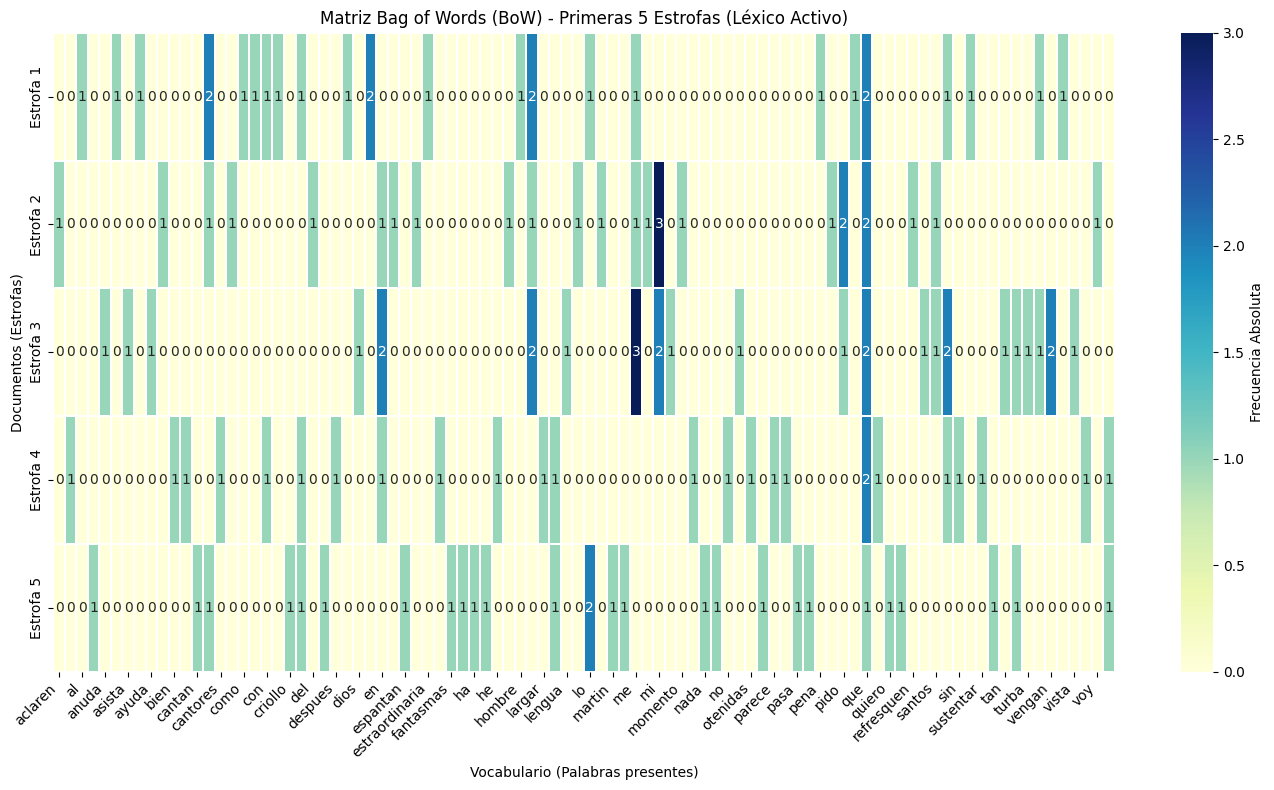

In [ ]:
# 3. Seleccionar un subconjunto representativo para visualización (primeras 5 estrofas)
subset_docs = df_bow_full.iloc[:5]
# Filtrar palabras que aparecen al menos una vez en estas estrofas
present_terms = subset_docs.columns[(subset_docs > 0).any(axis=0)]
subset_df = subset_docs[present_terms]

plt.figure(figsize=(14, 8))
sns.heatmap(
    subset_df,
    annot=True,
    fmt='d',
    cmap='YlGnBu',
    cbar_kws={'label': 'Frecuencia Absoluta'},
    linewidths=0.2
)
plt.title('Matriz Bag of Words (BoW) - Primeras 5 Estrofas (Léxico Activo)')
plt.ylabel('Documentos (Estrofas)')
plt.xlabel('Vocabulario (Palabras presentes)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Proyección 2D de Palabras usando PCA (BoW)

Para demostrar que bajo la representación de **Bag of Words** las palabras morfológicamente o semánticamente similares no necesariamente se agrupan cerca (ya que cada término es una dimensión ortogonal en el espacio original), vamos a:
1. Utilizar la matriz transpuesta de BoW (donde cada palabra es un vector de características a lo largo de las 398 estrofas).
2. Seleccionar un grupo de palabras clave interesantes (incluyendo variaciones de verbos, sinónimos y palabras no relacionadas).
3. Aplicar **PCA** para reducir la dimensión a 2D.
4. Graficar los vectores resultantes para analizar su distribución espacial.

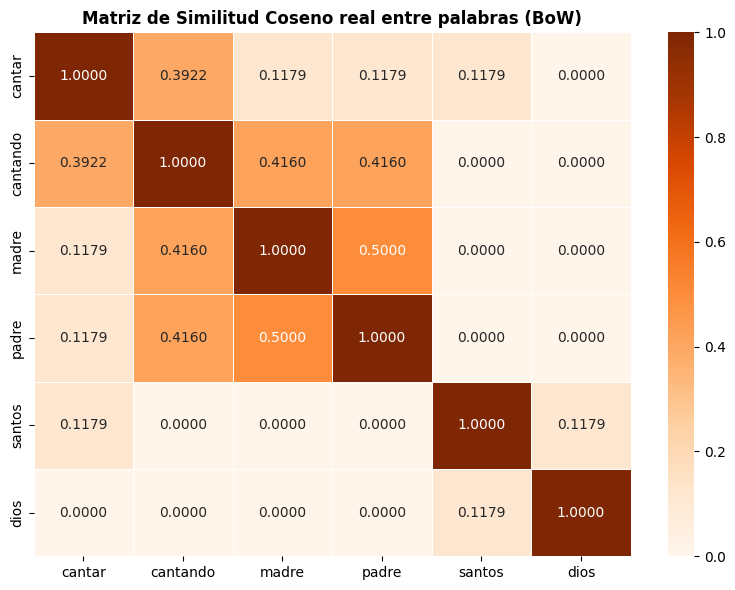

In [ ]:
# 1. Obtener la matriz transpuesta: Palabras como filas, Documentos (estrofas) como columnas
# df_bow_full tiene dimensiones (398 estrofas, 2786 palabras)
words_matrix = df_bow_full.T

# 2. Seleccionar palabras específicas para comparar en el gráfico
palabras_objetivo = [
    'cantar', 'cantando',
    'madre', 'padre',
    'santos', 'dios'
]

# Filtrar solo aquellas que existan en nuestro vocabulario
palabras_filtradas = [w for w in palabras_objetivo if w in words_matrix.index]

# Extraer sus vectores de frecuencia en las estrofas
words_vectors = [bow.get_word_vector(word=w_target) for w_target in palabras_objetivo]

# Calculamos la similitud coseno entre los vectores de las palabras seleccionadas
# words_vectors tiene forma (6, 398)
sim_matrix = cosine_similarity(words_vectors)

# Convertir a DataFrame para una lectura amigable
df_sim = pd.DataFrame(sim_matrix, index=palabras_filtradas, columns=palabras_filtradas)

# Graficar la matriz de similitud como un mapa de calor
plt.figure(figsize=(8, 6))
sns.heatmap(
    df_sim,
    annot=True,
    cmap='Oranges',
    vmin=0,
    vmax=1,
    linewidths=0.5,
    fmt='.4f'
)
plt.title('Matriz de Similitud Coseno real entre palabras (BoW)', fontsize=12, weight='bold')
plt.tight_layout()
plt.show()

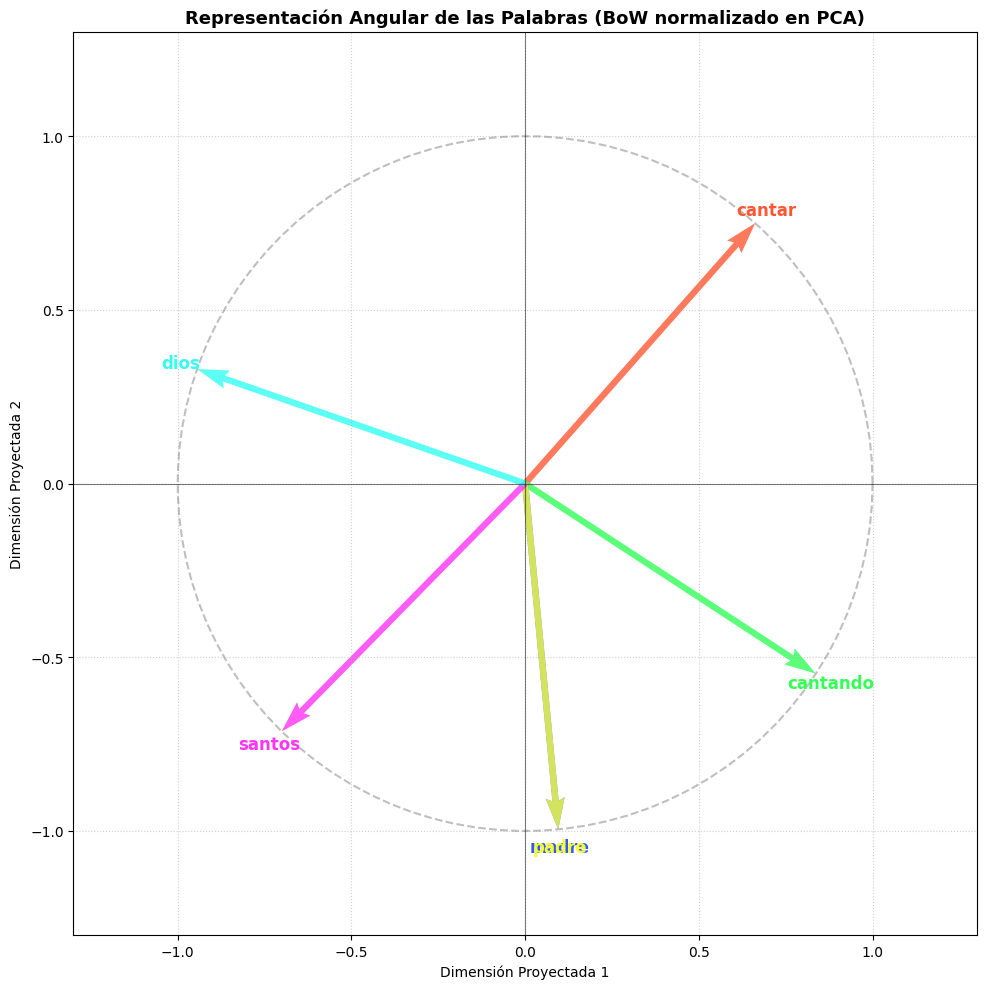

In [ ]:
# 1. Aplicamos PCA de 2 componentes a los vectores originales de las palabras
pca = PCA(n_components=2, random_state=42)
coords_2d = pca.fit_transform(words_vectors)

# 2. Normalizamos los vectores en 2D para que todos tengan longitud (norma) 1.
# De esta forma, la distancia en el gráfico se traduce puramente en términos de ángulo.
norms = np.linalg.norm(coords_2d, axis=1, keepdims=True)
# Evitamos la división por cero si hubiera algún vector nulo
norms[norms == 0] = 1
coords_normalized = coords_2d / norms

# 3. Graficar los vectores saliendo desde el origen (0, 0)
plt.figure(figsize=(10, 10))

# Dibujar el círculo unitario para referencia de norma 1
theta = np.linspace(0, 2*np.pi, 100)
plt.plot(np.cos(theta), np.sin(theta), color='gray', linestyle='--', alpha=0.5, label='Círculo Unitario')

# Dibujar cada palabra como un vector (flecha)
colores = ['#FF5733', '#33FF57', '#3357FF', '#F3FF33', '#FF33F3', '#33FFF0']
for idx, palabra in enumerate(palabras_filtradas):
    x, y = coords_normalized[idx]
    # Dibujar la flecha
    plt.quiver(0, 0, x, y, angles='xy', scale_units='xy', scale=1,
               color=colores[idx % len(colores)], alpha=0.8, width=0.007)
    # Etiqueta al final del vector
    plt.text(x * 1.05, y * 1.05, palabra, fontsize=12, weight='bold',
             color=colores[idx % len(colores)], ha='center', va='center')

# Ajustes estéticos
plt.xlim(-1.3, 1.3)
plt.ylim(-1.3, 1.3)
plt.axhline(0, color='black', linewidth=0.8, alpha=0.5)
plt.axvline(0, color='black', linewidth=0.8, alpha=0.5)
plt.grid(True, linestyle=':', alpha=0.6)
plt.gca().set_aspect('equal')

plt.title('Representación Angular de las Palabras (BoW normalizado en PCA)', fontsize=13, weight='bold')
plt.xlabel('Dimensión Proyectada 1', fontsize=10)
plt.ylabel('Dimensión Proyectada 2', fontsize=10)
plt.tight_layout()
plt.show()

### Limitaciones del Modelo Bag of Words (BoW)

A pesar de su sencillez y utilidad en tareas básicas de clasificación o recuperación de información, el modelo Bag of Words presenta problemas fundamentales:

1. **Pérdida del orden y la estructura sintáctica:** Al tratar el texto como una "bolsa" de palabras, se destruye la gramática. Las oraciones *"el perro muerde al hombre"* y *"el hombre muerde al perro"* generan vectores idénticos.
2. **Problema de la Ortogonalidad (Sin semántica):** Las palabras se tratan como dimensiones independientes. Palabras sinónimas o morfológicamente emparentadas (como *cantar*, *cantando*, *cantan*) no comparten ninguna cercanía matemática implícita.
3. **Ambigüedad por Homogeneidad Vectorial (Vectores Idénticos):** Dos palabras completamente distintas que aparecen exactamente la misma cantidad de veces y en las mismas estrofas tendrán **exactamente el mismo vector** en el modelo, haciéndolas indistinguibles para cualquier métrica de distancia o similitud.

In [ ]:
# Encontrar palabras diferentes con vectores idénticos en el corpus

# Agrupamos las palabras (columnas) que tienen exactamente los mismos valores a lo largo de todas las estrofas
vectors_dict = defaultdict(list)

for word in df_bow_full.columns:
    # Convertimos el vector de la palabra a una tupla para poder usarla como clave de diccionario
    vector_tuple = tuple(df_bow_full[word].values)
    # Solo nos interesan palabras que aparezcan al menos 2 veces en total para evitar palabras ultra-raras
    if sum(vector_tuple) >= 2:
        vectors_dict[vector_tuple].append(word)

# Filtrar aquellos vectores que son compartidos por más de una palabra
identical_pairs = {words[0]: words[1:] for vector, words in vectors_dict.items() if len(words) > 1}

# Mostrar ejemplos de colisión vectorial
if identical_pairs:
    print("🔍 ¡Parejas de palabras sin relación que tienen vectores BoW IDENTICOS!\n")

    # Seleccionamos hasta 3 ejemplos interesantes
    for i, (word1, synonyms) in enumerate(list(identical_pairs.items())[:3]):
        word2 = synonyms[0]

        # Obtener el vector de una de ellas para ver su presencia
        vec = df_bow_full[word1].values
        estrofas_donde_aparece = [f"Estrofa {idx+1}" for idx, val in enumerate(vec) if val > 0]

        print(f"Ejemplo {i+1}:")
        print(f"  • Palabra A: '{word1}'")
        print(f"  • Palabra B: '{word2}'")
        print(f"  • Frecuencia e Historial: Aparecen {sum(vec)} veces en el corpus, exactamente en: {estrofas_donde_aparece}")

        # Validar su Similitud Coseno
        vec_a = df_bow_full[[word1]].T
        vec_b = df_bow_full[[word2]].T
        sim = cosine_similarity(vec_a, vec_b)[0][0]
        print(f"  • Similitud Coseno calculada: {sim:.4f} (1.0 = Idénticos)\n")
else:
    print("No se encontraron palabras con vectores idénticos y frecuencia >= 2 en este corpus.")

🔍 ¡Parejas de palabras sin relación que tienen vectores BoW IDENTICOS!

Ejemplo 1:
  • Palabra A: 'altivo'
  • Palabra B: 'vivo'
  • Frecuencia e Historial: Aparecen 2 veces en el corpus, exactamente en: ['Estrofa 20', 'Estrofa 250']
  • Similitud Coseno calculada: 1.0000 (1.0 = Idénticos)

Ejemplo 2:
  • Palabra A: 'broma'
  • Palabra B: 'toma'
  • Frecuencia e Historial: Aparecen 2 veces en el corpus, exactamente en: ['Estrofa 234', 'Estrofa 345']
  • Similitud Coseno calculada: 1.0000 (1.0 = Idénticos)

Ejemplo 3:
  • Palabra A: 'dejarlo'
  • Palabra B: 'resollar'
  • Frecuencia e Historial: Aparecen 2 veces en el corpus, exactamente en: ['Estrofa 275', 'Estrofa 320']
  • Similitud Coseno calculada: 1.0000 (1.0 = Idénticos)



### ¿Cómo generar texto con BoW?

BoW **no preserva el orden de las palabras**, así que no puede "generar" texto de forma directa como un modelo de lenguaje. Sin embargo, podemos usarlo para aplicaciones reales muy útiles:

- **Recuperación de estrofas similares**: dado un texto de consulta, encontrar las estrofas más parecidas en el corpus.

### Similitud de Coseno sobre Vectores BoW

Para comparar dos documentos vectorizados con BoW, la métrica más usada es la **Similitud de Coseno**:

$$\text{sim}(d_i, d_j) = \frac{\mathbf{v}_i \cdot \mathbf{v}_j}{\|\mathbf{v}_i\| \cdot \|\mathbf{v}_j\|}$$

donde $\mathbf{v}_i$ y $\mathbf{v}_j$ son los vectores BoW de los documentos $d_i$ y $d_j$.


**Intuición geométrica:** Imagina que cada documento es una flecha en un espacio de $N$ dimensiones
(una por cada palabra del vocabulario). El coseno mide el **ángulo** entre esas flechas — si dos documentos
hablan de lo mismo, sus flechas apuntan en la misma dirección ($\cos\theta \approx 1$).

In [ ]:
# ── Motor de Búsqueda con BoW ──
# Dado un texto de consulta, encontrar las 3 estrofas más similares del corpus

# Consulta de prueba
query = 'cantar pena solitaria voy'
print(f"🔍 Consulta: '{query}'\n")
print('📜 Estrofas más similares según BoW:\n')

# Obtiene los índices de las mejores coincidencias
resultados = bow.search_similar(query, 5)
for j, (idx, sim) in enumerate(resultados, 1):
    print(f'[{j}] Similitud: {sim:.4f} (Estrofa {idx+1})')
    print(f'     {cleaned_documents[idx][:180]}...')
    print()

🔍 Consulta: 'cantar pena solitaria voy'

📜 Estrofas más similares según BoW:

[1] Similitud: 0.3381 (Estrofa 1)
     aqui me pongo a cantar al compas de la viguela, que el hombre que lo desvela una pena estraordinaria, como la ave solitaria con el cantar se consuela....

[2] Similitud: 0.1796 (Estrofa 297)
     y con algunos ardiles voy viviendo, aunque rotoso; a veces me hago el sarnoso y no tengo ni un granito, pero al chifle voy ganoso como panzon al maiz frito....

[3] Similitud: 0.1667 (Estrofa 2)
     pido a los santos del cielo que ayuden mi pensamiento, les pido en este momento que voy a cantar mi historia me refresquen la memoria y aclaren mi entendimiento....

[4] Similitud: 0.1622 (Estrofa 7)
     que no se trabe mi lengua ni me falte la palabra— el cantar mi gloria labra y poniendome a cantar, cantando me han de encontrar aunque la tierra se abra....

[5] Similitud: 0.1179 (Estrofa 26)
     y apenas el horizonte empezaba a coloriar, los pajaros a cantar, y las gallinas a ap

### Material Complementario
- [Bag of Words ¡EXPLICADO! | Procesamiento del Lenguaje Natural](https://www.youtube.com/watch?v=xkUaoOEnHf0)
- [A Gentle Introduction to the Bag-of-Words Model](https://machinelearningmastery.com/gentle-introduction-bag-words-model/)
- [¿Qué es la bolsa de palabras?](https://www.ibm.com/mx-es/think/topics/bag-of-words)